In [1]:
import matplotlib.pyplot as plt        # plotting
import numpy as np                     # numerical arrays and np.pi
from qiskit import QuantumCircuit                 # the object we build circuits with
from qiskit.visualization import plot_histogram   # bar chart of measurement counts
import math
from math import gcd                   # greatest common divisor
from numpy.random import randint       # random integers
import pandas as pd                    # tables (DataFrame) for printing results
from fractions import Fraction         # exact rational numbers; .limit_denominator() = continued fractions
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns
print("Imports Successful")


Imports Successful


In [2]:
# Define the number to be factored (N)
N = 15

# Define the number of qubits needed to store the number N
n = math.ceil(math.log(N, 2))

# Define the number of qubits needed to store the value of a
m = 2 * n
a = 3

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `math.ceil(math.log(N, 2))` | the number of bits of N, rounded up: 4 for N = 15 (a 4-qubit work register) |
| `m = 2 * n` | the textbook choice of counting qubits, 2n = 8: enough for the continued-fraction step to be reliable (2^m ≥ N²) |
| `a = 3` | the base; note that gcd(3, 15) = 3 ≠ 1, so the plot below finds no period — it is a lucky hit, the factor is already there |

</details>


In [3]:
print(N,n,m,a)

15 4 8 3


Could not find period, check a < N and have no common factors.


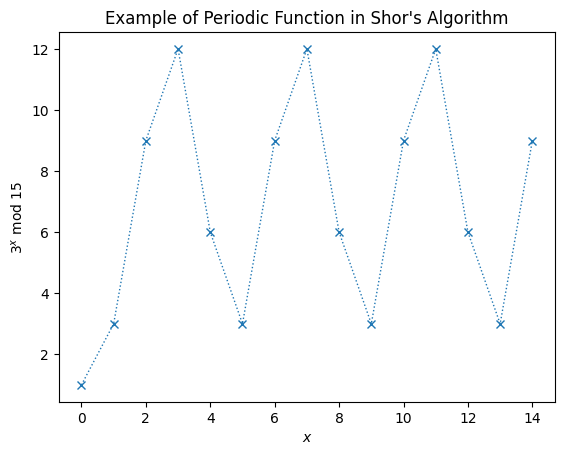

In [4]:
# Calculate the plotting data
xvals = np.arange(N)                         # NumPy array 0, 1, ..., N-1
yvals = [np.mod(a**x, N) for x in xvals]     # list comprehension: a^x mod N for every x

# Use matplotlib to display it nicely
fig, ax = plt.subplots()                     # one figure with one set of axes
ax.plot(xvals, yvals, linewidth=1, linestyle='dotted', marker='x')
ax.set(xlabel='$x$', ylabel=f'${a}^x$ mod ${N}$',          # f-string: {a} and {N} are replaced by their values
       title="Example of Periodic Function in Shor's Algorithm")
try: # plot r on the graph
    r = yvals[1:].index(1) + 1               # first x > 0 with a^x mod N == 1, i.e. the period r
    plt.annotate('', xy=(0,1), xytext=(r,1),
                 arrowprops=dict(arrowstyle='<->'))
    plt.annotate(f'$r={r}$', xy=(r/3,1.5))
except ValueError:                           # list.index() raises ValueError if 1 never appears
    print('Could not find period, check a < N and have no common factors.')


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.mod(a**x, N)` | aˣ mod N computed the slow way (aˣ first, then the remainder); `pow(a, x, N)` would reduce as it goes |
| `[... for x in xvals]` | a list comprehension: one value per x |
| `yvals[1:].index(1) + 1` | the first x ≥ 1 with aˣ ≡ 1, i.e. the period; `ValueError` if 1 never appears (gcd(a, N) ≠ 1, as here) |
| `plt.annotate` | the double arrow spans one period r |

</details>


## Implementation of period finding
In this example we will solve the period finding problem for $a=7$ and $N=15$
. We provide the circuits for 
 where:
$U|y\rangle = |ay\bmod 15\rangle$ without explanation. To create $U^x$ , we will simply repeat the circuit $x$ 
 times. In the next section we will discuss a general method for creating these circuits efficiently. The function c_amod15 returns the controlled-U gate for a, repeated power times.

In [5]:
# Specify variables
N_COUNT = 8  # number of counting qubits
a = 7

In [6]:
def c_amod15(a, power):
    """Controlled multiplication by a mod 15"""
    if a not in [2,4,7,8,11,13]:
        raise ValueError("'a' must be 2,4,7,8,11 or 13")   # raise = abort with an error message
    U = QuantumCircuit(4)                 # a 4-qubit circuit (no classical bits): the work register
    # Textbook version: apply U `power` times in a row (slow for large powers; see shor.ipynb for the
    # classical shortcut). U.swap(i, j) exchanges qubits i and j, U.x(q) applies a NOT to qubit q.
    for _iteration in range(power):
        if a in [2,13]:
            U.swap(2,3)
            U.swap(1,2)
            U.swap(0,1)
        if a in [7,8]:
            U.swap(0,1)
            U.swap(1,2)
            U.swap(2,3)
        if a in [4, 11]:
            U.swap(1,3)
            U.swap(0,2)
        if a in [7,11,13]:
            for q in range(4):
                U.x(q)
    U = U.to_gate()                       # pack the circuit into a single reusable Gate object
    U.name = f"{a}^{power} mod 15"        # label shown in circuit drawings
    c_U = U.control()                     # add one control qubit -> controlled-U
    return c_U


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(4)` | 4 qubits, no classical bits: the work register that stores y ∈ {0, …, 15} |
| `for _iteration in range(power)` | the textbook construction: U applied `power` times in a row — 128 copies for the last counting qubit (`shor.ipynb` computes a^power mod 15 classically instead) |
| `U.swap(i, j)`, `U.x(q)` | the swaps permute the bits of y (a cyclic shift = ×2, ×4, ×8 mod 15), the X gates complement them (y → 15 − y) |
| `U.to_gate()`, `.name`, `.control()` | circuit → gate → controlled gate: one box with a control wire in the drawings |

</details>


In [7]:
def qft_dagger(n):
    """n-qubit QFTdagger the first n qubits in circ"""
    qc = QuantumCircuit(n)
    # Don't forget the Swaps!
    for qubit in range(n//2):                        # reverse the qubit order
        qc.swap(qubit, n-qubit-1)
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi/float(2**(j-m)), m, j)      # qc.cp(theta, control, target): controlled phase gate
        qc.h(j)                                      # Hadamard on qubit j
    qc.name = "QFT†"                                 # label shown in circuit drawings
    return qc


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc.swap(qubit, n-qubit-1)` | reverse the qubit order: the QFT outputs its bits in reverse |
| `qc.cp(-np.pi/2**(j-m), m, j)` | controlled-phase with angle −π/2^(j−m): the conjugate of the QFT's phases, hence the dagger |
| `qc.h(j)` | a Hadamard after the phases of qubit j |
| `qc.name = "QFT†"` | the label of the box in the drawings |

</details>


Let us look at the two building blocks before assembling them. `draw('mpl')` renders a circuit with
matplotlib. A gate has no `draw()`, so for the controlled multiplication we draw `base_gate.definition`
(the circuit of $U$ without its control); `decompose()` expands composite gates by one level.


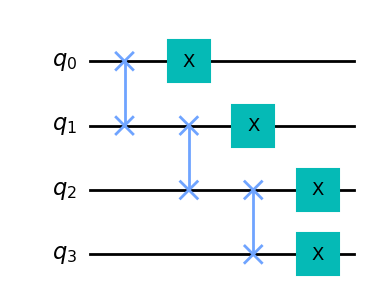

↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) and four X gates (complement = 15 − y): 7y = 15 − 8y mod 15


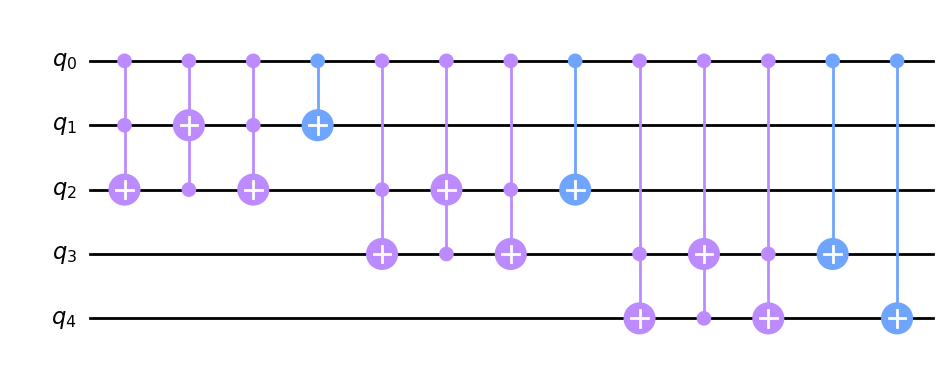

↑ controlled-U after decompose(): controlled SWAPs became Toffoli (ccx) + CNOT gates — {'ccx': 9, 'cx': 4}


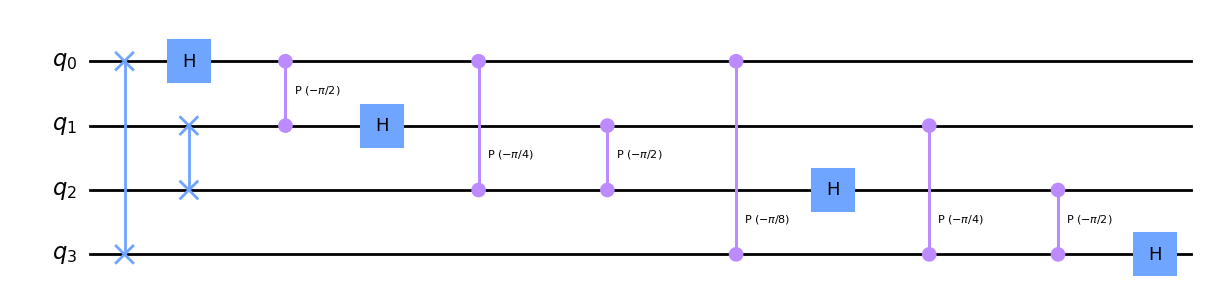

↑ QFT† on 4 qubits: swaps reverse the qubit order, then Hadamards interleaved with controlled phases −π/2, −π/4, −π/8


In [8]:
# U for a = 7, power = 1: multiplication by 7 mod 15 on the 4-qubit work register
display(draw(c_amod15(7, 1).base_gate.definition))   # .base_gate = the gate without its control; .definition = the circuit it was built from
print("↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) and four X gates (complement = 15 − y): 7y = 15 − 8y mod 15")

# The controlled version inside a 5-qubit circuit (qubit 0 = control), expanded one level
cU = QuantumCircuit(5)
cU.append(c_amod15(7, 1), [0, 1, 2, 3, 4])    # append(gate, qubits): control first, then the 4 work qubits
display(draw(cU.decompose())); print(f"↑ controlled-U after decompose(): controlled SWAPs became Toffoli (ccx) + CNOT gates — {dict(cU.decompose().count_ops())}")

# The inverse QFT on 4 qubits
display(draw(qft_dagger(4))); print("↑ QFT† on 4 qubits: swaps reverse the qubit order, then Hadamards interleaved with controlled phases −π/2, −π/4, −π/8")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `gate.base_gate.definition` | a controlled gate remembers the gate it controls; a custom gate remembers the circuit it was built from |
| `cU.append(gate, [0, 1, 2, 3, 4])` | place the gate on named qubits: control first |
| `decompose()` | expand composite gates one level: controlled SWAP → Toffoli + CNOT |
| `draw(qc)` | our helper around `qc.draw("mpl")`; `display()` shows a figure that is not the last line of the cell |

</details>


In [9]:
# Create QuantumCircuit with N_COUNT counting qubits
# plus 4 qubits for U to act on
qc = QuantumCircuit(N_COUNT + 4, N_COUNT)   # QuantumCircuit(number_of_qubits, number_of_classical_bits)

# Initialize counting qubits
# in state |+>
for q in range(N_COUNT):
    qc.h(q)                                 # Hadamard on qubit q

# And auxiliary register in state |1>
qc.x(N_COUNT)                               # NOT on the first work qubit

# Do controlled-U operations
for q in range(N_COUNT):
    # qc.append(gate, qubits): the list names the qubits the gate acts on, control first
    qc.append(c_amod15(a, 2**q),
             [q] + [i+N_COUNT for i in range(4)])

# Do inverse-QFT
qc.append(qft_dagger(N_COUNT), range(N_COUNT))

# Measure circuit
qc.measure(range(N_COUNT), range(N_COUNT))  # measure(qubits, classical_bits): qubit q -> bit q
print(f"{qc.num_qubits} qubits, {qc.num_clbits} classical bits, depth {qc.depth()}")


12 qubits, 8 classical bits, depth 11


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(N_COUNT + 4, N_COUNT)` | counting register + 4-qubit work register; N_COUNT classical bits |
| `qc.h(q)`, `qc.x(N_COUNT)` | \|+⟩ on every counting qubit; \|1⟩ on the work register (its least significant qubit) |
| `qc.append(c_amod15(a, 2**q), [q] + [...])` | controlled-U^(2^q) with counting qubit q as control: the QPE pattern |
| `qc.append(qft_dagger(N_COUNT), range(N_COUNT))` | the inverse QFT reads the phase into the counting register |
| `qc.measure(range(N_COUNT), range(N_COUNT))` | qubit q → classical bit q |

</details>


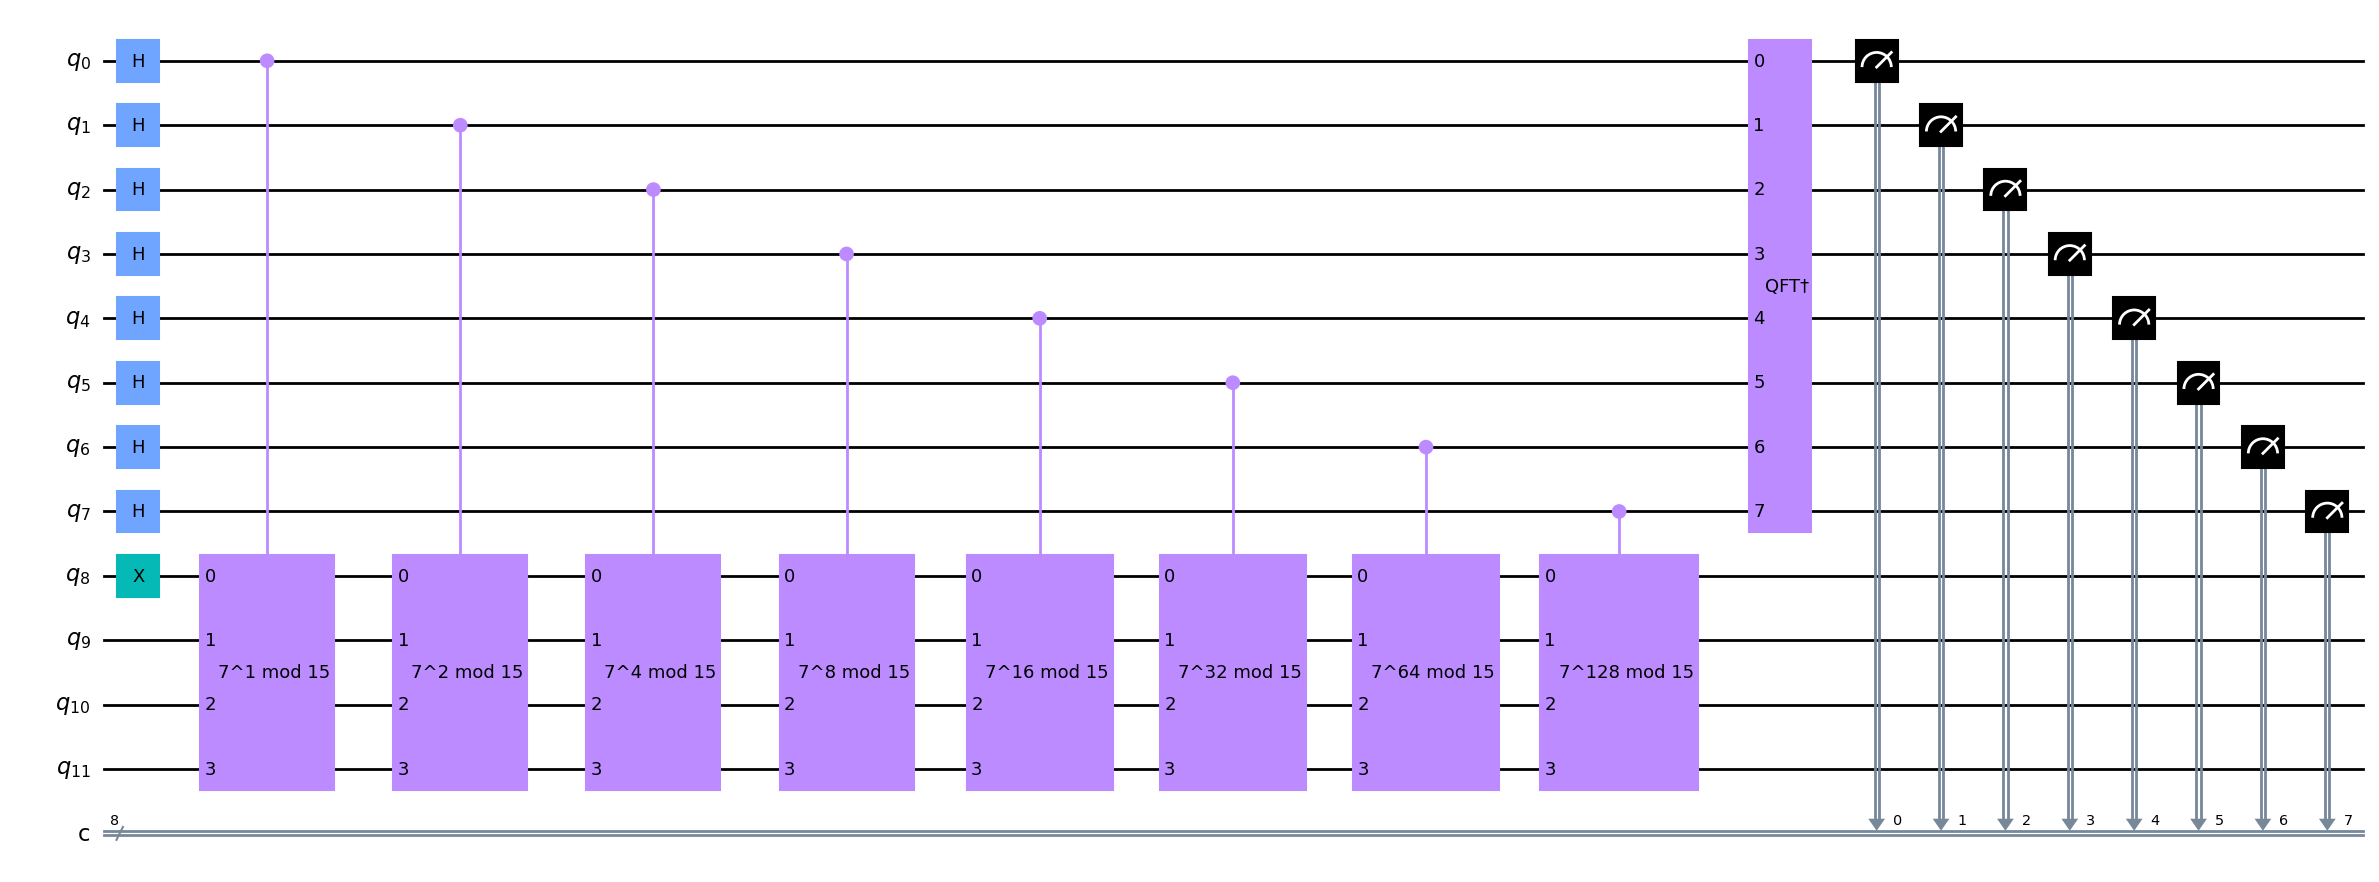

↑ the order-finding circuit: 8 counting qubits (top), 4 work qubits (bottom); each box is controlled-U^(2^q), the last box is QFT†


In [10]:
display(draw(qc)); print(f"↑ the order-finding circuit: {N_COUNT} counting qubits (top), 4 work qubits (bottom); each box is controlled-U^(2^q), the last box is QFT†")


In [11]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler
from qiskit_aer import AerSimulator                                                # local simulator
from qiskit_aer.primitives import SamplerV2 as Sampler                             # (primitive interface, not used below)


In [12]:
sampler = Sampler()
# The circuit needs to be transpiled to the AerSimulator target
pass_manager = generate_preset_pass_manager(3, AerSimulator())   # optimization_level 3 = most aggressive
qc_isa_circuit = pass_manager.run(qc)                            # rewrite qc with the backend's native gates
print(f"transpiled: {qc_isa_circuit.size()} gates, depth {qc_isa_circuit.depth()}")
#isa_observable = observable.apply_layout(isa_circuit.layout)


transpiled: 3368 gates, depth 3297


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(3, AerSimulator())` | the transpiler for this backend; optimisation level 3 = most aggressive |
| `pass_manager.run(qc)` | rewrite the circuit with the backend's basis gates: the 128 repeated U's of the last counting qubit become thousands of gates |
| `size()`, `depth()` | what actually runs; compare with the ~70 gates of `shor.ipynb`, which precomputes a^power classically |

</details>


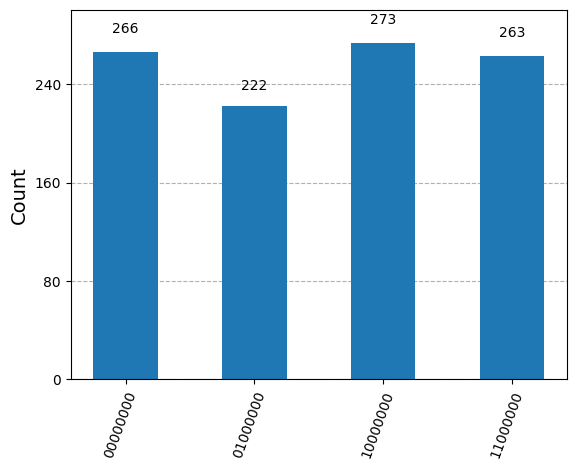

In [13]:
sim = AerSimulator()                            # local ideal simulator
results = sim.run(qc_isa_circuit).result()      # run (default 1024 shots) and wait for the result
counts = results.get_counts()                   # dict {'bitstring': how many shots gave it}

def run_circuit(circuit, shots=1024):
    """Transpile + run + counts in one call (used by the exercises at the end)."""
    return sim.run(pass_manager.run(circuit), shots=shots).result().get_counts()

plot_histogram(counts)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `AerSimulator().run(circuit)` | a job on the local simulator; `.result().get_counts()` returns {bitstring: count} |
| `shots` | left at the default 1024 repetitions here |
| `run_circuit(circuit, shots)` | transpile + run + counts in one call, for the exercises at the end |

</details>


In [14]:
rows, measured_phases = [], []
for output in counts:                 # iterating over a dict gives its keys: the measured bitstrings
    decimal = int(output, 2)  # Convert (base 2) string to decimal
    phase = decimal/(2**N_COUNT)  # Find corresponding eigenvalue
    measured_phases.append(phase)
    # Add these values to the rows in our table:
    rows.append([f"{output}(bin) = {decimal:>3}(dec)",     # :>3 = right-align in 3 characters
                 f"{decimal}/{2**N_COUNT} = {phase:.2f}"])   # :.2f = 2 decimal places
# Print the rows in a table
headers=["Register Output", "Phase"]
df = pd.DataFrame(rows, columns=headers)       # pandas table
print(df)


            Register Output           Phase
0  10000000(bin) = 128(dec)  128/256 = 0.50
1  11000000(bin) = 192(dec)  192/256 = 0.75
2  01000000(bin) =  64(dec)   64/256 = 0.25
3  00000000(bin) =   0(dec)    0/256 = 0.00


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `int(output, 2)` | base-2 string → integer; divided by 2^N_COUNT it is the phase φ |
| `f"{decimal:>3}"` | right-aligned in 3 characters |
| `pd.DataFrame(rows, columns=headers)` | a printable table; one row per distinct outcome |

</details>


In [15]:
rows = []
for phase in measured_phases:
    frac = Fraction(phase).limit_denominator(15)   # continued fractions: closest s/r with r <= 15
    rows.append([phase,
                 f"{frac.numerator}/{frac.denominator}",
                 frac.denominator])
# Print as a table
headers=["Phase", "Fraction", "Guess for r"]
df = pd.DataFrame(rows, columns=headers)
print(df)


   Phase Fraction  Guess for r
0   0.50      1/2            2
1   0.75      3/4            4
2   0.25      1/4            4
3   0.00      0/1            1


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `Fraction(phase).limit_denominator(15)` | the closest fraction with denominator ≤ 15 = the continued-fraction convergent; its denominator is the guess for r |
| `frac.numerator`, `frac.denominator` | s and r of the fraction s/r |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**From the measured phases to the factors, by hand.** With $a = 7$ and $N = 15$ the table shows four outcomes: $0,\ 64,\ 128,\ 192$ out of $256$, i.e. $\phi = 0,\ \tfrac14,\ \tfrac12,\ \tfrac34$.

* $\phi = \tfrac14 = [0;4]$ and $\phi = \tfrac34 = [0;1,3]$ give $r = 4$ ✓.
* $\phi = \tfrac12$ gives $r = 2$: a divisor of the true order ($s = 2$ and $r = 4$ share the factor 2). Check: $7^{2} = 49 \equiv 4 \ne 1$.
* $\phi = 0$ carries no information ($s = 0$).

With $r = 4$: $x = 7^{2} \bmod 15 = 4$, $\gcd(4 - 1, 15) = 3$ and $\gcd(4 + 1, 15) = 5$ — the cell below computes the first one and divides.

Two of four outcomes work, so each shot succeeds with probability about $\tfrac12$: the algorithm is probabilistic and is repeated until $a^{r} \equiv 1$ and the gcds are non-trivial.

</details>


We can see that two of the measured eigenvalues provided us with the correct result: $r=4$, and we can see that Shor’s algorithm has a chance of failing. 

In [16]:
r = 4

In [17]:
# Use the period r to calculate the factors of N using classical algorithms
gcd = math.gcd(a**(r//2)-1, N)   # // = integer division; math.gcd = Euclid's algorithm
factor1 = gcd
factor2 = N // gcd


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `a**(r//2) - 1` | x − 1 with x = a^{r/2}; `//` is integer division |
| `math.gcd(..., N)` | Euclid's algorithm: one factor of N; `N // gcd` is the other |

</details>


In [18]:
# Print the factors of N
print("The factors of", N, "are", factor1, "and", factor2)

The factors of 15 are 3 and 5


## 🔬 In-depth analysis

1. **Other bases.** Re-run the order-finding circuit with $a = 2, 8, 11, 13$. For every measured phase take `Fraction(phase).limit_denominator(15)` and keep the denominators $r$ with $a^r \equiv 1 \pmod{15}$. Which orders do you get, and which of them are even (usable)?
2. **Precision.** Rebuild the circuit with `N_COUNT = 4` and `N_COUNT = 10`. What fraction of the shots lands exactly on the four ideal outcomes $k\cdot 2^{N_{\rm COUNT}}/4$? Relate it to the rule $2^{N_{\rm COUNT}} \ge N^2$.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [19]:
# 🔬 In-depth analysis — your code here



(1) a =  2: candidates [1, 2, 4] -> r = 4 (even: usable)


(1) a =  8: candidates [1, 2, 4] -> r = 4 (even: usable)


(1) a = 11: candidates [1, 2] -> r = 2 (even: usable)


(1) a = 13: candidates [1, 2, 4] -> r = 4 (even: usable)
(2) N_COUNT =  4: 2^N_COUNT =    16 <  N^2 = 225; 100.0% of the shots on the four ideal peaks


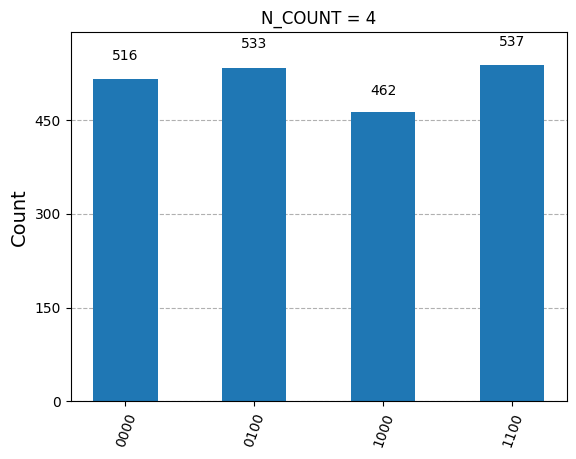

(2) N_COUNT = 10: 2^N_COUNT =  1024 >= N^2 = 225; 100.0% of the shots on the four ideal peaks


In [20]:
# Reference solution
def order_finding(a_, n_count):
    """The circuit of the cell above, as a function of a and of the number of counting qubits."""
    qc_ = QuantumCircuit(n_count + 4, n_count)
    qc_.h(range(n_count)); qc_.x(n_count)                                                 # h(range(...)) applies H to every qubit of the range at once
    for q in range(n_count): qc_.append(c_amod15(a_, 2 ** q), [q] + [i + n_count for i in range(4)])
    qc_.append(qft_dagger(n_count), range(n_count)); qc_.measure(range(n_count), range(n_count))
    return qc_

# (1) orders for the other bases
for a_ in (2, 8, 11, 13):
    cnt = run_circuit(order_finding(a_, N_COUNT), shots=512)
    cands = {Fraction(int(k, 2) / 2 ** N_COUNT).limit_denominator(15).denominator for k in cnt}   # candidate orders from all phases
    good = sorted(r_ for r_ in cands if r_ > 1 and pow(a_, r_, 15) == 1)                           # those with a^r = 1 mod 15
    r_ = min(good) if good else None
    print(f"(1) a = {a_:2d}: candidates {sorted(cands)} -> r = {r_} ({'even: usable' if r_ and r_ % 2 == 0 else 'odd or none: retry'})")

# (2) precision vs number of counting qubits
for n_ in (4, 10):
    cnt = run_circuit(order_finding(7, n_), shots=2048)
    peaks = {k * 2 ** n_ // 4 for k in range(4)}                                                    # ideal outcomes for r = 4
    on_peak = sum(v for k, v in cnt.items() if int(k, 2) in peaks) / sum(cnt.values())
    print(f"(2) N_COUNT = {n_:2d}: 2^N_COUNT = {2 ** n_:5d} {'>=' if 2 ** n_ >= 15 ** 2 else '< '} N^2 = 225; {on_peak:.1%} of the shots on the four ideal peaks")
    if n_ <= 8: display(plot_histogram(cnt, title=f"N_COUNT = {n_}"))


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc_.h(range(n_count))` | a gate method accepts a list or range of qubits: one call, many gates |
| `{... for k in cnt}` | a set comprehension over the bitstrings: every phase becomes a candidate order, duplicates vanish |
| `pow(a_, r_, 15) == 1` | the test that separates the true order from artefacts of the rounding |
| `sum(...) / sum(cnt.values())` | the fraction of shots on the ideal peaks: it drops with few counting qubits (coarse phase) and on noisy hardware |

</details>
